In [227]:
from dotenv import load_dotenv
load_dotenv()

True

In [228]:
from langchain_groq import ChatGroq
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph,START,END
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

In [229]:
llm = ChatGroq(model="openai/gpt-oss-120b",streaming="True")

In [230]:
class MailState(BaseModel):
    query: str= ""
    draft: str= ""
    human_feedback: str = ""
    final_response: str = ""


In [231]:
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver
from typing import Literal

def DraftEmail(state: MailState) -> MailState:
    if state.human_feedback:
        draft = llm.invoke(f"""
            Rewrite this draft email for: {state.query}

            Previously generated draft:
            {state.draft}

            Human feedback to apply:
            {state.human_feedback}

            Return the complete revised email.
        """).content
    else:
        draft = llm.invoke(state.query).content

    state.draft = draft
    return state


def HumanFeedBack(state: MailState) -> MailState:
    feedback = interrupt({
        "draft_email": state.draft,
        "question": "Do you want to continue or re-write the mail?"
    })

    fb = str(feedback or "").strip().lower().strip(".,!?")

    if fb in ("approved", "ok", "yes", "continue"):
        state.human_feedback = ""
    else:
        state.human_feedback = str(feedback)

    return state

def finalize_node(state: MailState):
    print("Email sent successfully")
    return {
        "draft": "Email sent successfully",
        "final_response": "Email sent successfully"
    }
    
def conditional_routing(state: MailState) -> Literal["draft", "final"]:
    if state.human_feedback:
        return "draft"
    return "final"

In [232]:
graph_builder=StateGraph(MailState)

##node
graph_builder.add_node("draft",DraftEmail)
graph_builder.add_node("human_fb",HumanFeedBack)
graph_builder.add_node("final",finalize_node)

##edges
graph_builder.add_edge(START,"draft")
graph_builder.add_edge("draft","human_fb")
graph_builder.add_conditional_edges("human_fb",conditional_routing)
graph_builder.add_edge("final",END)

graph=graph_builder.compile(checkpointer=InMemorySaver())




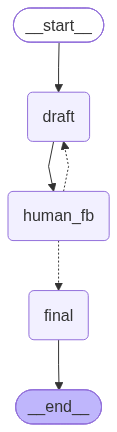

In [233]:
from IPython.display import Image
Image(graph.get_graph().draw_mermaid_png())

In [234]:
config = {"configurable": {"thread_id": "hh-2"}}

res = graph.invoke(
    {
        "query": "Create a simple medical leave request email as a student to the Principal of St. Joseph College, Darjeeling, for 10th November to 15th November."
    },
    config=config
)

print(res["draft"])


**Subject:** Request for Medical Leave (10 Nov – 15 Nov)

Dear Principal,

I hope this message finds you well. I am writing to inform you that, due to a medical condition, I will be unable to attend classes from **10 November to 15 November**. My doctor has advised a period of rest and treatment during these dates, and I have attached the medical certificate for your reference.

I kindly request your approval for this leave of absence. I will make sure to catch up on any missed assignments and lectures promptly upon my return.

Thank you for your understanding and consideration.

Yours sincerely,

[Your Name]  
[Class / Section] – e.g., 12‑B  
Roll No.: [Your Roll Number]  
St. Joseph College, Darjeeling  

*Attachment: Medical Certificate*


In [235]:
res = graph.invoke(
    Command(resume="Change the principal name to Mr. Ram Kumar Thapa."),
    config=config
)

print(res["draft"])

**Subject:** Request for Medical Leave (10 Nov – 15 Nov)

Dear Mr. Ram Kumar Thapa,

I hope this message finds you well. I am writing to inform you that, due to a medical condition, I will be unable to attend classes from **10 November to 15 November**. My doctor has advised a period of rest and treatment during these dates, and I have attached the medical certificate for your reference.

I kindly request your approval for this leave of absence. I will make sure to catch up on any missed assignments and lectures promptly upon my return.

Thank you for your understanding and consideration.

Yours sincerely,

[Your Name]  
Class / Section: 12‑B  
Roll No.: [Your Roll Number]  
St. Joseph College, Darjeeling  

*Attachment: Medical Certificate*


In [236]:
res = graph.invoke(
    Command(resume="Change the Full Name into Sawal Gautam"),
    config=config
)

print(res["draft"])

**Subject:** Medical Leave Request (10 Nov – 15 Nov)

Dear Mr. Ram Kumar Thapa,

I hope you are well. I am writing to inform you that, due to a medical condition, I will be unable to attend classes from **10 November to 15 November**. My doctor has advised rest and treatment during this period, and I have attached the medical certificate for your reference.

I kindly request your approval for this leave. I will catch up on any missed assignments and lectures promptly upon my return.

Thank you for your understanding.

Yours sincerely,

**Sawal Gautam**  
Class / Section: 12‑B  
Roll No.: [Your Roll Number]  
St. Joseph College, Darjeeling  

*Attachment: Medical Certificate*


In [237]:
res = graph.invoke(
    Command(resume="Approved."),
    config=config
)

print(res)

Email sent successfully
{'query': 'Create a simple medical leave request email as a student to the Principal of St. Joseph College, Darjeeling, for 10th November to 15th November.', 'draft': 'Email sent successfully', 'human_feedback': '', 'final_response': 'Email sent successfully'}
